# COMP20008 Assignment 2: Superhost status

**Research question:** Can `host_is_superhost` be predicted from listing and host attributes, and which features matter most?

Put the original Melbourne `listings.csv` (Inside Airbnb release labelled 16 June 2026) beside this notebook or in a `data/` folder, then restart the kernel and run all cells. A full run takes several minutes, mostly for model tuning.

We evaluate predictions on listings belonging to unseen hosts and compare tree importance with mutual information to identify influential features. Removing review-derived features is a secondary check of how much the models rely on review information. The models predict recorded status in this snapshot. They say nothing about future eligibility or what causes a host to become a Superhost.

**GenAI acknowledgement:** Claude, OpenAI Codex and Cursor assisted with writing code based on the group members' specifications, requirements and decisions. Group members reviewed and accepted all code and are responsible for it.

## 1. Setup

We use pandas and numpy for data handling, scikit-learn for the models and metrics, and matplotlib/seaborn for figures. Results were produced with pandas 3.0.6, numpy 2.5.3, scikit-learn 1.9.1, scipy 1.18.1, matplotlib 3.11.2 and seaborn 0.13.2; other versions can change the last decimal places.

[`pd.set_option`](https://pandas.pydata.org/docs/reference/api/pandas.set_option.html) controls table display; [`sns.set_palette`](https://seaborn.pydata.org/generated/seaborn.set_palette.html) selects figure colours.

`SEED` fixes every random step (the shuffled splits, the decision tree's tie-breaking, mutual information noise and the bootstrap), so a rerun gives the same numbers. 20008 is just the subject code; any fixed number would do.

Every table is also saved as a CSV in `notebook_outputs/tables/` and every figure as a PNG in `notebook_outputs/figures/`, so the report can use them directly. The two small helpers `show` and `save_figure` do that. [`DataFrame.to_csv`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.to_csv.html) writes a table; `index=False` leaves out its row labels. [`Figure.tight_layout`](https://matplotlib.org/stable/api/_as_gen/matplotlib.figure.Figure.tight_layout.html) adjusts spacing, [`Figure.savefig`](https://matplotlib.org/stable/api/_as_gen/matplotlib.figure.Figure.savefig.html) saves the image (`dpi=200` sets resolution; `bbox_inches='tight'` trims empty margins), and [`plt.show`](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.show.html) displays it. [`os.makedirs`](https://docs.python.org/3/library/os.html#os.makedirs) with `exist_ok=True` creates the folders only if they do not already exist.

In [1]:
# GenAI acknowledgement: Claude, OpenAI Codex and Cursor assisted with code
# based on group members' specifications, requirements and decisions.
# Group members reviewed and accepted all code and are responsible for it.
import itertools
import json
import os

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
from scipy.stats import bootstrap as scipy_bootstrap
import seaborn as sns
import sklearn
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score,
                             mutual_info_score, normalized_mutual_info_score,
                             precision_recall_fscore_support, roc_auc_score, roc_curve)
from sklearn.metrics.pairwise import haversine_distances
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree

print('pandas', pd.__version__, '| numpy', np.__version__, '| scikit-learn', sklearn.__version__,
      '| scipy', scipy.__version__, '| matplotlib', matplotlib.__version__, '| seaborn', sns.__version__)

SEED = 20008
TARGET = 'host_is_superhost'

pd.set_option('display.max_columns', None)  # show every column of wide result tables
sns.set_palette('colorblind')                # colours that remain distinguishable for colour-blind readers

os.makedirs('notebook_outputs/tables', exist_ok=True)
os.makedirs('notebook_outputs/figures', exist_ok=True)

def show(table, name):
    # Save a results table as CSV and display it in the notebook.
    table.to_csv(f'notebook_outputs/tables/{name}.csv', index=False)
    display(table)

def save_figure(fig, name):
    # Save a figure as PNG at print resolution and display it.
    fig.tight_layout()
    fig.savefig(f'notebook_outputs/figures/{name}.png', dpi=200, bbox_inches='tight')
    plt.show()

pandas 3.0.6 | numpy 2.5.3 | scikit-learn 1.9.1 | scipy 1.18.1 | matplotlib 3.11.2 | seaborn 0.13.2


## 2. Read the raw data

The file should have 25,728 listings and 90 columns. We check two things before any modelling:

- **Collection dates.** `last_scraped` shows the listings were collected on several dates. The table below shows that later batches have far more missing `price` and `beds` values and fewer Superhosts, so missingness partly reflects how the data was collected, not only host behaviour. This helps us avoid interpreting missingness flags as purely host behaviour. `batches` and `batch_table` are summaries, not model inputs; later subgroup checks use `raw['last_scraped']` directly.
- **Missing values** in the 19 raw source columns that feed our model features. `used_columns` is this missingness-check list, not all columns accessed by the notebook. We chose a manageable set covering host scale and verification, listing operations, size/location and reviews. Conversions and additional flags turn these 19 source columns into 26 model predictors. Other fields may also be useful; we have not tested all 90 columns. IDs, the target and audit fields are handled separately. The report outline records the feature-scope rationale. The all-null check uses [`DataFrame.all`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.all.html) to check that every row in a column is missing.

[`pd.read_csv`](https://pandas.pydata.org/docs/reference/api/pandas.read_csv.html) reads the plain CSV. We look in `data/` and beside the notebook. [`os.path.exists`](https://docs.python.org/3/library/os.path.html#os.path.exists) checks whether each path exists. [`DataFrame.assign`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.assign.html) adds temporary True/False summary columns; [`reset_index`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.reset_index.html) turns the grouped row labels back into a column. [`DataFrame.groupby`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.groupby.html) with [named aggregation](https://pandas.pydata.org/docs/reference/api/pandas.api.typing.DataFrameGroupBy.agg.html) (`new_column=(source_column, function)`) computes one summary row per scrape date. The mean of a True/False column is the share of True values. In the loading loop, `break` stops at the first file that exists. [`Series.value_counts`](https://pandas.pydata.org/docs/reference/api/pandas.Series.value_counts.html) counts each value; `dropna=False` includes missing values, and [`to_dict`](https://pandas.pydata.org/docs/reference/api/pandas.Series.to_dict.html) displays the counts as value/count pairs.

In [2]:
for data_path in ['data/listings.csv', 'listings.csv']:
    if os.path.exists(data_path):
        break
raw = pd.read_csv(data_path)
print(f'{raw.shape[0]:,} rows, {raw.shape[1]} columns; {raw.host_id.nunique():,} hosts; '
      f'{(raw[TARGET] == "t").mean():.1%} of listings belong to a Superhost')
print(f'host_is_superhost=True: {(raw[TARGET] == "t").sum():,} listings')
print(f'host_is_superhost=False: {(raw[TARGET] == "f").sum():,} listings')

empty_columns = raw.columns[raw.isna().all()]
print(f"Columns with all {len(raw):,} values missing:", empty_columns.tolist())

for column in ['scrape_id', 'has_availability']:
    print(column, raw[column].value_counts(dropna=False).to_dict())

# batches stores 4 more columns on top of raw, with boolean values 
batches = raw.assign(
    superhost=raw[TARGET] == 't', 
    beds_missing=raw.beds.isna(),
    price_missing=raw.price.isna(), 
    never_reviewed=raw.number_of_reviews == 0
)

# batch_table groups the batches by the last_scraped column and aggregates some columns
batch_table = batches.groupby('last_scraped').agg(
    listings=('id', 'size'), 
    superhost_share=('superhost', 'mean'),
    beds_missing_share=('beds_missing', 'mean'), 
    price_missing_share=('price_missing', 'mean'),
    never_reviewed_share=('never_reviewed', 'mean')
).reset_index()

show(batch_table, 'collection_batches')

used_columns = ['host_listings_count', 'host_identity_verified', 'room_type', 'accommodates', 'bedrooms',
                'beds', 'bathrooms_text', 'amenities', 'latitude', 'longitude', 'price', 'minimum_nights',
                'availability_365', 'number_of_reviews', 'reviews_per_month', 'last_review',
                'review_scores_rating', 'review_scores_cleanliness', 'review_scores_value']
missing = raw[used_columns].isna().sum()
show(pd.DataFrame({'column': used_columns, 'missing_rows': missing.values,
                   'missing_share': (missing / len(raw)).values}), 'raw_missingness')

25,728 rows, 90 columns; 14,113 hosts; 30.6% of listings belong to a Superhost
host_is_superhost=True: 7,885 listings
host_is_superhost=False: 17,843 listings
Columns with all 25,728 values missing: ['neighborhood_overview', 'host_since', 'host_response_time', 'host_response_rate', 'host_acceptance_rate', 'host_thumbnail_url', 'host_neighbourhood', 'host_total_listings_count', 'host_verifications', 'neighbourhood', 'neighbourhood_group_cleansed', 'calendar_updated', 'license', 'instant_bookable']
scrape_id {20260616211523: 25728}
has_availability {'t': 25580, nan: 148}


,last_scraped,listings,superhost_share,beds_missing_share,price_missing_share,never_reviewed_share
0,2026-06-17,18884,0.381805,0.011438,0.012921,0.148962
1,2026-06-28,670,0.191045,1.000000,0.813433,0.219403
2,2026-06-29,6173,0.088450,1.000000,0.933744,0.245748
3,2026-07-01,1,1.000000,0.000000,0.000000,0.000000


,column,missing_rows,missing_share
0,host_listings_count,0,0.000000
1,host_identity_verified,0,0.000000
2,room_type,0,0.000000
3,accommodates,0,0.000000
4,bedrooms,4679,0.181864
5,beds,7059,0.274370
6,bathrooms_text,26,0.001011
7,amenities,0,0.000000
8,latitude,0,0.000000
9,longitude,0,0.000000


## 3. Preprocessing: build the feature table

This section turns the raw listings into the table the models use. The report discusses three choices in depth. The other steps only turn text into numbers.

**Three Preprocessing Tasks**

1. **How recent the last review is.** `last_review` is text. We turn it into a date and count the days since that review. The count starts from the latest review date in this file. The code finds that date and prints it, so the numbers stay the same if the notebook is run again later, and no listing gets a negative number of days.

2. **Listings with no reviews.** 4,477 listings have never been reviewed, so they have no recency, no review frequency and no review scores. We keep these rows and add a `never_reviewed` column (1 = no reviews, 0 = reviewed). Section 4 fills `days_since_last_review`, `reviews_per_month` and the review scores with the median of the training listings that actually have that value, so a never-reviewed listing is given a typical reviewed listing's recency rather than zero or a blank. `never_reviewed` stays 1, so the model can tell a filled value from a real review.

3. **Missing price, bedrooms or beds.** We keep these rows too, and add a 0/1 column that records the missing value. Section 4 fills bedrooms and beds with the median for that listing's `room_type`, because a private room and an entire home are different sizes. Price uses one median from all training listings.

**Mechanistic conversion to numbers**

These are not separate tasks. There is no real alternative to compare:

- price text such as `$1,250.00` becomes a number

- bathroom text such as `1.5 shared baths` becomes a number

- the amenities list becomes a count of items

- latitude and longitude become kilometres to the Melbourne CBD

- `room_type` becomes four 0/1 columns, one per category

- `t` / `f` becomes 1 / 0

- a flag for hosts with more than one listing, kept so the result can be compared with the earlier trial run

**Considered, then not used:** grouping the many property types, banding minimum stay, and banding distance to the CBD. The table below says why.

**Functions**

- `.astype(int)` turns True or False into 1 or 0. The models need numbers.

- `.str.replace` deletes `$` and `,` from a price. `.astype(float)` then makes it a number. A missing price stays missing.

- `.equals` checks whether two columns match, including missing values in the same rows. The notebook prints this for minimum nights and for the cleaned nightly price.

- `pd.to_datetime` reads a date such as `2026-06-28`. `.max()` finds the latest review date in the file. Subtracting each review from that date, then taking `.dt.days`, gives a whole number of days. A missing date stays missing, so before training starts a never-reviewed listing has no recency.

- `.str.extract` takes the first number out of bathroom text, so `1.5 shared baths` becomes 1.5. We first rewrite `half-bath` as `0.5 bath`, so `Shared half-bath` becomes a number too.

- `json.loads` reads the amenities cell as a list, and `len` counts the items. The loop does this once per row.

- Distance to the CBD uses the scikit-learn’s [`haversine_distances`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.pairwise.haversine_distances.html) function to calculate distance along the Earth's surface. `np.radians` converts latitude and longitude from degrees to radians, as required by `haversine_distances`. The function returns angular distances; multiplying by the radius gives kilometres. `.ravel()` turns the one-column result into a flat array for the dataframe column. Our fixed reference point is the published Geo Point for the City of Melbourne's ‘Melbourne (CBD)’ CLUE area, rounded to six decimal places (−37.813811, 144.962915) ([City of Melbourne, 2026](https://data.melbourne.vic.gov.au/explore/dataset/small-areas-for-census-of-land-use-and-employment-clue/)). We approximate Earth as a sphere with a mean radius of 6371.0088 km ([Moritz, 2000](https://geoweb.mit.edu/~tah/12.221_2005/grs80_corr.pdf)).

- `pd.get_dummies` makes one 0/1 column per room type, joined on with `pd.concat`. This does not pretend that one room type is larger than another, which matters because KNN uses distances (EdStem #186).


In [3]:
# Start with a minimal feature set
features = pd.DataFrame({'id': raw['id'], 'host_id': raw['host_id'], 'room_type': raw['room_type']})
features[TARGET] = (raw[TARGET] == 't').astype(int)

# Task 1: review recency, in days before the latest review date in the file.
last_review = pd.to_datetime(raw['last_review'], format='%Y-%m-%d')
reference_date = last_review.max()
print('Latest review date:', reference_date.date())
features['days_since_last_review'] = (reference_date - last_review).dt.days

# Task 2: listings without any review keep their row; a flag marks them.
features['never_reviewed'] = raw['last_review'].isna().astype(int)
review_columns = ['number_of_reviews', 'reviews_per_month', 'review_scores_rating',
                  'review_scores_cleanliness', 'review_scores_value']
features[review_columns] = raw[review_columns]

# Task 3: price and room size, with flags recording which values were missing.
features['price_clean'] = raw['price'].str.replace('$', '').str.replace(',', '').astype(float)
print('Duplicate minimum nights:', raw['minimum_nights'].equals(raw['minimum_minimum_nights']))
print('Duplicate nightly price:', features['price_clean'].equals(raw['price_quote_price_per_night']))
features['price_missing'] = features['price_clean'].isna().astype(int)
features['bedrooms'] = raw['bedrooms']
features['beds'] = raw['beds']
features['bedrooms_missing'] = raw['bedrooms'].isna().astype(int)
features['beds_missing'] = raw['beds'].isna().astype(int)

# Supporting conversions.
features['host_listings_count'] = raw['host_listings_count']
features['is_multi_listing_host'] = (raw['host_listings_count'] > 1).astype(int)
features['host_identity_verified'] = (raw['host_identity_verified'] == 't').astype(int)
stay_columns = ['availability_365', 'minimum_nights', 'accommodates']
features[stay_columns] = raw[stay_columns]

bathrooms = raw['bathrooms_text'].str.lower().str.replace('half-bath', '0.5 bath')
features['bathrooms_numeric'] = bathrooms.str.extract(r'(\d+\.?\d*)').astype(float)

amenity_counts = []
for text in raw['amenities']:
    amenity_list = json.loads(text)
    amenity_counts.append(len(amenity_list))
features['amenities_count'] = amenity_counts

# Haversine function returns angular distance in radians:
listing_coords = np.radians(raw[['latitude', 'longitude']])
# Melbourne (CBD) CLUE Geo Point, rounded to 6 decimal places (City of Melbourne, 2026).
# https://data.melbourne.vic.gov.au/explore/dataset/small-areas-for-census-of-land-use-and-employment-clue/
cbd_coords = np.radians([[-37.813811, 144.962915]])
# Multiply by mean Earth radius in km (Moritz, 2000); ravel makes the column a flat array.
# https://doi.org/10.1007/s001900050278
features['dist_cbd_km'] = haversine_distances(listing_coords, cbd_coords).ravel() * 6371.0088

room_dummies = pd.get_dummies(raw['room_type'], dtype=int).rename(columns={
    'Entire home/apt': 'room_type__entire_home_apt', 'Private room': 'room_type__private_room',
    'Shared room': 'room_type__shared_room', 'Hotel room': 'room_type__hotel_room'})
features = pd.concat([features, room_dummies], axis=1)

print('Recency computed for', features['days_since_last_review'].notna().sum(), 'listings;',
      features['never_reviewed'].sum(), 'never reviewed')


Latest review date: 2026-06-28
Duplicate minimum nights: True
Duplicate nightly price: True


Recency computed for 21251 listings; 4477 never reviewed


**Preprocessing candidates.** The specification asks us to name at least six candidates and implement three. The table gives the count behind each decision.

We did not group the many `property_type` labels, because `room_type` already encodes size/type more simply. We did not band `minimum_nights`, because only a small group requires 30+ nights, so we keep it as a number. We did not band distance to the CBD, because the cut-points would be arbitrary; the continuous distance stays in the table.


> **FOR ELLEN ONLY:** Please recheck the comment that all other transformations are encoding: counting amenities and calculating CBD distance also construct features.

In [4]:
candidates = pd.DataFrame([
    ('Review recency', 'Selected', raw['last_review'].notna().sum(), 'Reviewed listings with a parsed date'),
    ('Absent review information', 'Selected', features['never_reviewed'].sum(), 'Never-reviewed listings kept, flagged and median-filled'),
    ('Missing price and room size', 'Selected', raw[['price', 'bedrooms', 'beds']].isna().any(axis=1).sum(), 'Rows missing price, bedrooms or beds; kept, flagged and median-filled'),
    ('Host-scale flag', 'Supporting conversion', features['is_multi_listing_host'].sum(), 'Multi-listing host rows; kept for comparability with the sprint'),
    ('Property-type consolidation', 'Not selected', raw['property_type'].nunique(), 'Number of property types; room type is simpler'),
    ('Minimum-stay bands', 'Not selected', (raw['minimum_nights'] >= 30).sum(), 'Listings with minimum stay of 30+ nights'),
    ('CBD-distance bands', 'Not selected', round(features['dist_cbd_km'].median(), 2), 'Median CBD distance (km); kept continuous'),
], columns=['candidate', 'decision', 'count_or_median_km', 'meaning'])
show(candidates, 'preprocessing_candidates')

,candidate,decision,count_or_median_km,meaning
0,Review recency,Selected,21251.00,Reviewed listings with a parsed date
1,Absent review information,Selected,4477.00,"Never-reviewed listings kept, flagged and medi..."
2,Missing price and room size,Selected,9960.00,"Rows missing price, bedrooms or beds; kept, fl..."
3,Host-scale flag,Supporting conversion,15252.00,Multi-listing host rows; kept for comparabilit...
4,Property-type consolidation,Not selected,82.00,Number of property types; room type is simpler
5,Minimum-stay bands,Not selected,426.00,Listings with minimum stay of 30+ nights
6,CBD-distance bands,Not selected,5.11,Median CBD distance (km); kept continuous


The main model uses `full`, all 26 selected predictors.

As an optional secondary check, `no_review` removes the three review scores and all review-activity columns: `number_of_reviews`, `reviews_per_month`, `days_since_last_review` and `never_reviewed`.

This compares reliance on review information, rather than preprocessing or imputation strategies. No review retains 19 predictors covering host scale/verification, listing structure, amenities, location, stay/availability and missingness flags. IDs, the target and collection date are excluded from both predictor matrices.


In [5]:
review_quality = ['review_scores_rating', 'review_scores_cleanliness', 'review_scores_value']
review_activity = ['never_reviewed', 'number_of_reviews', 'reviews_per_month', 'days_since_last_review']
host_operation = ['host_listings_count', 'is_multi_listing_host', 'host_identity_verified',
                  'availability_365', 'minimum_nights', 'price_clean', 'price_missing']
listing_structure = ['room_type__entire_home_apt', 'room_type__private_room', 'room_type__shared_room',
                     'room_type__hotel_room', 'accommodates', 'bedrooms', 'bedrooms_missing', 'beds',
                     'beds_missing', 'bathrooms_numeric', 'amenities_count', 'dist_cbd_km']

CONDITIONS = {
    'full': review_quality + review_activity + host_operation + listing_structure,
    'no_review': host_operation + listing_structure,
}

show(pd.DataFrame([{'condition': name, 'n_features': len(cols), 'features': ', '.join(cols)}
                   for name, cols in CONDITIONS.items()]), 'feature_conditions')

,condition,n_features,features
0,full,26,"review_scores_rating, review_scores_cleanlines..."
1,no_review,19,"host_listings_count, is_multi_listing_host, ho..."


## 4. Train/test split and filling missing values

This is the train/test split plus missing-value handling from class. We split first, then compute fill-in values from the training rows only.

**Split.** About 30.6% of listings are Superhost, so a random split could put a very different mix in the test set. We use a stratified split so that share stays close to 30.6% in training and in test. We also keep every listing from the same host together (all in training, or all in test). Superhost is a host-level label: if the same host appeared on both sides, the model could memorise that host instead of learning general patterns. This is still 5-fold stratified cross-validation, as in the Week 9 workshop, with that extra host rule. We shuffle with a fixed seed so the same hosts land in the same place every run.

We make five folds and treat the first fold as the held-out test set (about 20% of listings). The other 80% is split again into five stratified, host-grouped folds. Those inner folds are only for choosing k and tree size. `.iloc` selects rows by position, because the splitter returns positions, not listing IDs.

**Filling missing values (no leakage).** Medians must come from the rows used to fit the model. If we used the test set to compute a median, test information would leak into training. The `impute` function therefore always takes a fitting table and an evaluation table:

- bedrooms and beds: training median within each `room_type` (a private room is not the same size as an entire home). If a room type has no observed value in the fitting rows, we use the overall fitting median;
- other numeric columns: one training median per column (`fillna`).

We use the median rather than the mean because price, counts and review frequency are skewed (a few very large values would pull a mean up). `.copy()` stops the function from editing the original tables.

**Function documentation:** [`StratifiedGroupKFold`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedGroupKFold.html), [`next`](https://docs.python.org/3/library/functions.html#next), [`.iloc`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.iloc.html), [`Series.map`](https://pandas.pydata.org/docs/reference/api/pandas.Series.map.html), [`DataFrame.fillna`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.fillna.html).

> **FOR ELLEN ONLY:** Please distinguish the outer held-out split from cross-validation: only the first outer fold is used as a fixed test set. Five-fold cross-validation runs inside the remaining training data.

In [6]:
outer_split = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
train_idx, test_idx = next(outer_split.split(features, features[TARGET], groups=features['host_id']))
train_frame = features.iloc[train_idx]
test_frame = features.iloc[test_idx]

inner_split = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
folds = list(inner_split.split(train_frame, train_frame[TARGET], groups=train_frame['host_id']))

shared_hosts = set(train_frame['host_id']) & set(test_frame['host_id'])
print('Hosts in both training and test sets:', len(shared_hosts))

show(pd.DataFrame([{'split': name, 'rows': len(frame), 'hosts': frame['host_id'].nunique(),
                    'superhost_rows': frame[TARGET].sum(), 'superhost_share': frame[TARGET].mean()}
                   for name, frame in [('train', train_frame), ('test', test_frame)]]), 'split_balance')

fold_rows = []
for fold, (fit_idx, val_idx) in enumerate(folds, start=1):
    val_rows = train_frame.iloc[val_idx]
    fold_rows.append({'fold': fold, 'training_rows': len(fit_idx), 'validation_rows': len(val_idx),
                      'validation_superhost_share': val_rows[TARGET].mean(),
                      'validation_hosts': val_rows['host_id'].nunique()})
show(pd.DataFrame(fold_rows), 'cv_fold_balance')

Hosts in both training and test sets: 0


,split,rows,hosts,superhost_rows,superhost_share
0,train,20582,11292,6308,0.306481
1,test,5146,2821,1577,0.306452


,fold,training_rows,validation_rows,validation_superhost_share,validation_hosts
0,1,16465,4117,0.306534,2259
1,2,16466,4116,0.306365,2258
2,3,16465,4117,0.306534,2258
3,4,16466,4116,0.306608,2259
4,5,16466,4116,0.306365,2258


In [7]:
def impute(fit_rows, eval_rows, columns):
    # Fill missing values using medians learned from fit_rows only.
    fit_rows, eval_rows = fit_rows.copy(), eval_rows.copy()
    for col in ['bedrooms', 'beds']:
        room_medians = fit_rows.groupby('room_type')[col].median()
        overall_median = fit_rows[col].median()
        fit_rows[col] = fit_rows[col].fillna(fit_rows['room_type'].map(room_medians)).fillna(overall_median)
        eval_rows[col] = eval_rows[col].fillna(eval_rows['room_type'].map(room_medians)).fillna(overall_median)
    medians = fit_rows[columns].median()
    return fit_rows[columns].fillna(medians), eval_rows[columns].fillna(medians)

# Before/after check on the full feature set: every gap should be filled.
X_train_full, X_test_full = impute(train_frame, test_frame, CONDITIONS['full'])
check_columns = ['days_since_last_review', 'reviews_per_month', 'review_scores_rating', 'price_clean', 'bedrooms', 'beds']
show(pd.DataFrame({'feature': check_columns,
                   'train_missing_before': train_frame[check_columns].isna().sum().values,
                   'train_missing_after': X_train_full[check_columns].isna().sum().values,
                   'test_missing_before': test_frame[check_columns].isna().sum().values,
                   'test_missing_after': X_test_full[check_columns].isna().sum().values}),
     'preprocessing_before_after')

,feature,train_missing_before,train_missing_after,test_missing_before,test_missing_after
0,days_since_last_review,3571,0,906,0
1,reviews_per_month,3571,0,906,0
2,review_scores_rating,3571,0,906,0
3,price_clean,5282,0,1271,0
4,bedrooms,3645,0,1034,0
5,beds,5655,0,1404,0


## 5. Correlation analysis

We use the host-activity set from the specification (Set C) plus the Superhost target:

- `host_listings_count`: how large the host's operation is
- `days_since_last_review`: how recent the last review is
- `reviews_per_month`: how often reviews arrive
- `review_scores_rating`: overall guest score
- `host_is_superhost`: the target

Five variables give ten pairs. For every pair we compute the four methods from class: Pearson, Spearman, mutual information (MI) and normalised mutual information (NMI).

We drop rows that are missing any of these five columns (`dropna`). That removes the 4,477 never-reviewed listings, because they have no recency, frequency or rating. The table therefore describes reviewed listings only.

- **Pearson** (`.corr`): linear association. When one variable is 0/1 (the target), this is the same formula as a point-biserial correlation. Pearson is a weak summary for a binary variable, so we read it together with Spearman and MI.
- **Spearman** (`method='spearman'`): correlation of ranks. It captures any increasing or decreasing relationship and is less pulled around by extreme listing counts.
- **MI and NMI**: these need categories. We divide percentile ranks into ten intervals. Ten is a simple choice that keeps some detail without creating too many categories. Tied values stay together, so the occupied bins can be fewer than ten and unequal in size. Different binning choices may change MI and NMI. The target is already 0/1. MI has no sign and is not on the same scale as Pearson. NMI rescales MI to roughly 0 to 1 so pairs are easier to compare.

Bin counts can be less than 10 when many listings share the same value: host listing count uses 8 bins and rating uses 9. We do not report p-values, because several listings can belong to one host, so rows are not independent. A second table repeats the same calculations on the training rows only. Any later modelling comment should use that training table, not the full-data table.

**Function documentation:** [`dropna`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.dropna.html), [`itertools.combinations`](https://docs.python.org/3/library/itertools.html#itertools.combinations), [`Series.corr`](https://pandas.pydata.org/docs/reference/api/pandas.Series.corr.html), [`mutual_info_score`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.mutual_info_score.html), [`normalized_mutual_info_score`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.normalized_mutual_info_score.html), [`Series.rank(pct=True)`](https://pandas.pydata.org/docs/reference/api/pandas.Series.rank.html), [`np.ceil`](https://numpy.org/doc/stable/reference/generated/numpy.ceil.html), [`pd.qcut`](https://pandas.pydata.org/docs/reference/api/pandas.qcut.html).

> **FOR ELLEN ONLY:** Please recheck “Pearson is a weak summary for a binary variable”: retain the EdStem #205 caution rather than implying a binary variable necessarily has weak association. The bin-count claims still need the proposed displayed calculations.

In [8]:
CORR_VARS = ['host_listings_count', 'days_since_last_review', 'reviews_per_month', 'review_scores_rating', TARGET]

def association_table(frame):
    complete = frame[CORR_VARS].dropna()
    # Convert percentile ranks into bin labels 0–9, keeping tied values together.
    binned = {col: (np.ceil(complete[col].rank(pct=True) * 10) - 1).astype(int) for col in CORR_VARS}
    binned[TARGET] = complete[TARGET]   # the target is already 0/1
    rows = []
    for a, b in itertools.combinations(CORR_VARS, 2):
        rows.append({'variable_a': a, 'variable_b': b,
                     'pearson': complete[a].corr(complete[b]),
                     'spearman': complete[a].corr(complete[b], method='spearman'),
                     'mi_nats': mutual_info_score(binned[a], binned[b]),
                     'nmi': normalized_mutual_info_score(binned[a], binned[b])})
    return pd.DataFrame(rows), complete

correlations, complete = association_table(features)
print(f'Correlation population: {len(complete):,} reviewed listings; {len(features) - len(complete):,} excluded')
show(correlations, 'correlation_all_pairs')
show(association_table(train_frame)[0], 'correlation_training_only')

Correlation population: 21,251 reviewed listings; 4,477 excluded


,variable_a,variable_b,pearson,spearman,mi_nats,nmi
0,host_listings_count,days_since_last_review,-0.113005,-0.194151,0.056933,0.027771
1,host_listings_count,reviews_per_month,-0.022511,0.149009,0.031369,0.015290
2,host_listings_count,review_scores_rating,-0.210010,-0.259708,0.050937,0.026248
3,host_listings_count,host_is_superhost,-0.068724,0.069924,0.013637,0.011121
4,days_since_last_review,reviews_per_month,-0.371946,-0.776556,0.462546,0.201021
5,days_since_last_review,review_scores_rating,-0.025113,-0.042186,0.062380,0.028483
6,days_since_last_review,host_is_superhost,-0.336714,-0.442502,0.115889,0.078535
7,reviews_per_month,review_scores_rating,0.148711,-0.014777,0.154023,0.070281
8,reviews_per_month,host_is_superhost,0.381093,0.466120,0.120804,0.081783
9,review_scores_rating,host_is_superhost,0.239257,0.218022,0.115365,0.084443


,variable_a,variable_b,pearson,spearman,mi_nats,nmi
0,host_listings_count,days_since_last_review,-0.159486,-0.211581,0.061091,0.029749
1,host_listings_count,reviews_per_month,0.043826,0.175253,0.035114,0.017092
2,host_listings_count,review_scores_rating,-0.181516,-0.257471,0.051878,0.026563
3,host_listings_count,host_is_superhost,-0.030982,0.070790,0.014542,0.011834
4,days_since_last_review,reviews_per_month,-0.369482,-0.768950,0.454650,0.197529
5,days_since_last_review,review_scores_rating,-0.024749,-0.036878,0.057588,0.026174
6,days_since_last_review,host_is_superhost,-0.334391,-0.428179,0.111329,0.075424
7,reviews_per_month,review_scores_rating,0.142368,-0.021409,0.146959,0.066766
8,reviews_per_month,host_is_superhost,0.367212,0.456525,0.116030,0.078563
9,review_scores_rating,host_is_superhost,0.237106,0.222723,0.112481,0.081777


## 6. Tune KNN and decision trees

This section is supervised learning: k-nearest neighbours and a decision tree, as required. Scaling is not a third model. It is a preprocessing step we try because KNN uses distances.

**Metric.** We tune with macro-F1: the average of the two classes' F1 scores. The Superhost class is about 31%, so accuracy can look high if we always predict "not Superhost" (about 69%). Macro-F1 treats both classes equally.

**What we try.** Every combination below is scored on the same five training folds, for each feature set (`full`, `no_review`). The grid includes the library defaults so we can measure the effect of changing them.

- KNN `n_neighbors` (k): odd values, so two-class votes do not tie. Small k follows a few neighbours (can overfit). Large k averages more neighbours (smoother). We keep equal vote weights and Euclidean distance (the defaults).
- Scaling: `StandardScaler` turns each column to mean 0 and standard deviation 1, fitted on the training fold only, then applied to the validation fold. Without scaling, a column in dollars or days dominates a 0/1 flag in KNN distance. Trees do not need this, because each split looks at one column.
- Decision tree `max_depth`: 2 to 20, plus unlimited (`None`, the default). `min_samples_leaf`: 1 (default), 5, 10, 20, 50. Both stop the tree from growing until every leaf is pure. The split rule stays at Gini (the default). A fixed `random_state` only makes tied splits reproducible.

Each fold is filled and scaled once, then every setting is fitted on that fold. We also store the training-fold score. A large gap between training F1 and validation F1 is overfitting.

We pick the setting with the highest mean validation macro-F1. In our run there were no exact ties at the top.

**Function documentation:** [`f1_score`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.f1_score.html), [`KNeighborsClassifier`](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsClassifier.html), [`StandardScaler`](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html), [`DecisionTreeClassifier`](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html), [`DataFrame.groupby`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.groupby.html), [`Series.idxmax`](https://pandas.pydata.org/docs/reference/api/pandas.Series.idxmax.html).

In result dictionaries, `**scores` copies the score entries into each row. `DataFrame.groupby` averages scores across folds; `sort=False` preserves grid order. `idxmax()` returns the first maximum.

In [9]:
K_VALUES = [1, 3, 5, 7, 9, 11, 15, 21, 31, 41, 51]
MAX_DEPTHS = [2, 3, 4, 5, 6, 8, 10, 12, 15, 20, None]
MIN_LEAF_SIZES = [1, 5, 10, 20, 50]

def fit_and_score(model, X_fit, y_fit, X_val, y_val):
    model.fit(X_fit, y_fit)
    return {'validation_f1': f1_score(y_val, model.predict(X_val), average='macro'),
            'training_f1': f1_score(y_fit, model.predict(X_fit), average='macro')}

knn_rows, tree_rows = [], []
for condition, columns in CONDITIONS.items():
    print('Tuning', condition, '...')
    for fold, (fit_idx, val_idx) in enumerate(folds, start=1):
        fit_rows, val_rows = train_frame.iloc[fit_idx], train_frame.iloc[val_idx]
        X_fit, X_val = impute(fit_rows, val_rows, columns)
        y_fit, y_val = fit_rows[TARGET], val_rows[TARGET]
        scaler = StandardScaler().fit(X_fit)
        X_fit_scaled, X_val_scaled = scaler.transform(X_fit), scaler.transform(X_val)

        for k in K_VALUES:
            for scaled in [True, False]:
                if scaled:
                    scores = fit_and_score(KNeighborsClassifier(n_neighbors=k), X_fit_scaled, y_fit, X_val_scaled, y_val)
                else:
                    scores = fit_and_score(KNeighborsClassifier(n_neighbors=k), X_fit, y_fit, X_val, y_val)
                knn_rows.append({'condition': condition, 'n_neighbors': k, 'scaled': scaled, 'fold': fold, **scores})

        for depth in MAX_DEPTHS:
            for leaf in MIN_LEAF_SIZES:
                tree = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=leaf, random_state=SEED)
                scores = fit_and_score(tree, X_fit, y_fit, X_val, y_val)
                # 'None' is stored as text so the table can group and display it.
                tree_rows.append({'condition': condition, 'max_depth': str(depth), 'min_samples_leaf': leaf,
                                  'fold': fold, **scores})

def average_folds(rows, settings):
    return (pd.DataFrame(rows).groupby(['condition'] + settings, sort=False)
            .agg(cv_macro_f1=('validation_f1', 'mean'), cv_macro_f1_sd=('validation_f1', 'std'),
                 train_macro_f1=('training_f1', 'mean'))
            .reset_index())

knn_cv = average_folds(knn_rows, ['n_neighbors', 'scaled'])
tree_cv = average_folds(tree_rows, ['max_depth', 'min_samples_leaf'])
print(len(knn_cv) + len(tree_cv), 'settings scored in total')

Tuning full ...


Tuning no_review ...


154 settings scored in total


**Grid score images:** The left panel is validation macro-F1 against k, with and without scaling. The right panel is a heatmap of the tree score for each depth and leaf size. The same numbers are saved as CSV tables so the report can show every value tried, not only the winner.

**Function documentation:** [`plt.subplots`](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.subplots.html), [`Axes.plot`](https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.plot.html), [`Axes.set`](https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.set.html), [`seaborn.heatmap`](https://seaborn.pydata.org/generated/seaborn.heatmap.html), [`DataFrame.pivot`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.pivot.html), [`Axes.legend`](https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.legend.html).

scaled,n_neighbors,False,True
0,1,0.656469,0.706185
1,3,0.673765,0.732770
2,5,0.687124,0.741453
3,7,0.692782,0.746666
4,9,0.697616,0.749091
5,11,0.700546,0.753256
6,15,0.704140,0.755861
7,21,0.704990,0.759433
8,31,0.707795,0.763202
9,41,0.709198,0.763181


max_depth,min_samples_leaf,2,3,4,5,6,8,10,12,15,20,None
0,1,0.752216,0.752674,0.766783,0.783782,0.779621,0.778012,0.766276,0.760707,0.741597,0.727009,0.721197
1,5,0.752216,0.752674,0.766783,0.783806,0.782062,0.781249,0.771433,0.764266,0.748692,0.738164,0.736032
2,10,0.752216,0.752674,0.766783,0.783761,0.781703,0.781629,0.776153,0.767373,0.755280,0.753443,0.752458
3,20,0.752216,0.752674,0.766879,0.781826,0.780458,0.781327,0.779266,0.773747,0.769708,0.770374,0.770374
4,50,0.752216,0.752674,0.769031,0.784988,0.783736,0.780868,0.779291,0.778807,0.778671,0.778671,0.778671


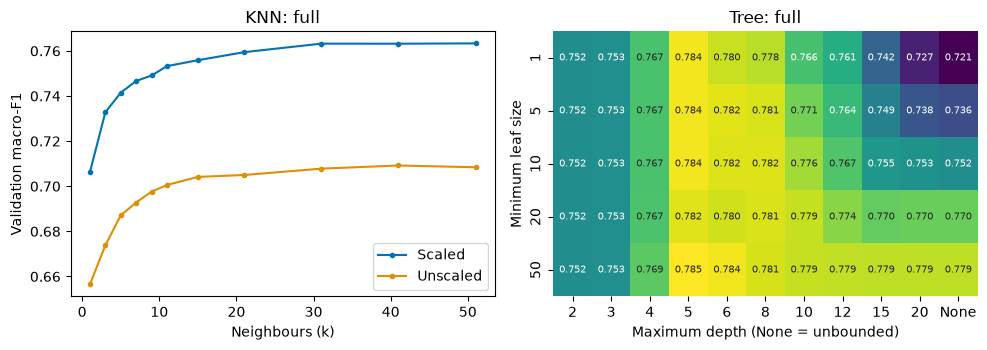

scaled,n_neighbors,False,True
0,1,0.598070,0.609953
1,3,0.612080,0.621285
2,5,0.622798,0.624644
3,7,0.625440,0.631489
4,9,0.630161,0.631206
5,11,0.628501,0.634029
6,15,0.631109,0.640122
7,21,0.633925,0.641783
8,31,0.629475,0.648941
9,41,0.631441,0.647855


max_depth,min_samples_leaf,2,3,4,5,6,8,10,12,15,20,None
0,1,0.409513,0.666916,0.666074,0.645392,0.656080,0.659928,0.658582,0.657031,0.639573,0.635549,0.612142
1,5,0.409513,0.666916,0.666074,0.645186,0.655342,0.659894,0.660426,0.659132,0.649920,0.640602,0.620458
2,10,0.409513,0.666916,0.666007,0.645245,0.655340,0.661632,0.666201,0.666450,0.655571,0.647102,0.630674
3,20,0.409513,0.666916,0.666007,0.645253,0.654243,0.665248,0.668062,0.669279,0.654293,0.647204,0.636727
4,50,0.409513,0.666916,0.669016,0.644052,0.654441,0.661503,0.663011,0.650457,0.644046,0.633157,0.632471


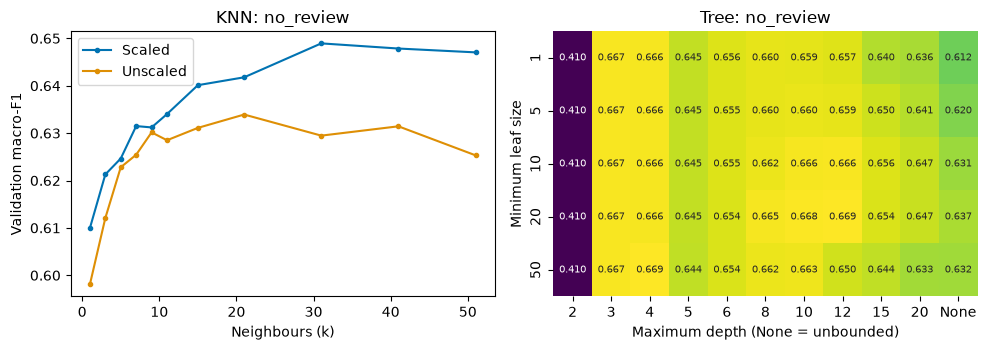

In [10]:
depth_labels = [str(d) for d in MAX_DEPTHS]
for condition in CONDITIONS:
    knn_grid = knn_cv[knn_cv['condition'] == condition].pivot(index='n_neighbors', columns='scaled', values='cv_macro_f1')
    tree_grid = (tree_cv[tree_cv['condition'] == condition]
                 .pivot(index='min_samples_leaf', columns='max_depth', values='cv_macro_f1')[depth_labels])
    show(knn_grid.reset_index(), f'knn_grid_{condition}')
    show(tree_grid.reset_index(), f'tree_grid_{condition}')

    fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
    axes[0].plot(knn_grid.index, knn_grid[True], marker='.', label='Scaled')
    axes[0].plot(knn_grid.index, knn_grid[False], marker='.', label='Unscaled')
    axes[0].set(xlabel='Neighbours (k)', ylabel='Validation macro-F1', title=f'KNN: {condition}')
    axes[0].legend()
    sns.heatmap(tree_grid, annot=True, fmt='.3f', cmap='viridis', cbar=False, annot_kws={'size': 7}, ax=axes[1])
    axes[1].set(xlabel='Maximum depth (None = unbounded)', ylabel='Minimum leaf size', title=f'Tree: {condition}')
    save_figure(fig, f'tuning_{condition}')

knn_cv.to_csv('notebook_outputs/tables/cv_results_knn.csv', index=False)
tree_cv.to_csv('notebook_outputs/tables/cv_results_tree.csv', index=False)

**Chosen settings, and what changes from the default.** For each hyperparameter we change, we put just that one back to its default, keep the others at the chosen values, and look up that combination's cross-validation score. The difference is the effect of that change. These differences should not be added together.

**Function documentation:** [`DataFrame.loc`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.loc.html).

In [11]:
chosen = {}   # chosen[(condition, model)] = selected hyperparameters
effect_rows = []
for condition in CONDITIONS:
    knn = knn_cv[knn_cv['condition'] == condition]
    best = knn.loc[knn['cv_macro_f1'].idxmax()]
    chosen[condition, 'knn'] = {'n_neighbors': int(best['n_neighbors']), 'scaled': bool(best['scaled'])}
    default_k = knn[(knn['n_neighbors'] == 5) & (knn['scaled'] == best['scaled'])]['cv_macro_f1'].iloc[0]
    unscaled = knn[(knn['n_neighbors'] == best['n_neighbors']) & (knn['scaled'] == False)]['cv_macro_f1'].iloc[0]
    effect_rows.append([condition, 'knn', 'n_neighbors', '5', best['n_neighbors'], best['cv_macro_f1'], default_k])
    effect_rows.append([condition, 'knn', 'scaled', 'False', best['scaled'], best['cv_macro_f1'], unscaled])

    tree = tree_cv[tree_cv['condition'] == condition]
    best = tree.loc[tree['cv_macro_f1'].idxmax()]
    depth = None if best['max_depth'] == 'None' else int(best['max_depth'])
    chosen[condition, 'decision_tree'] = {'max_depth': depth, 'min_samples_leaf': int(best['min_samples_leaf'])}
    default_depth = tree[(tree['max_depth'] == 'None') & (tree['min_samples_leaf'] == best['min_samples_leaf'])]['cv_macro_f1'].iloc[0]
    default_leaf = tree[(tree['max_depth'] == best['max_depth']) & (tree['min_samples_leaf'] == 1)]['cv_macro_f1'].iloc[0]
    effect_rows.append([condition, 'decision_tree', 'max_depth', 'None', best['max_depth'], best['cv_macro_f1'], default_depth])
    effect_rows.append([condition, 'decision_tree', 'min_samples_leaf', '1', best['min_samples_leaf'], best['cv_macro_f1'], default_leaf])

effects = pd.DataFrame(effect_rows, columns=['condition', 'model', 'parameter', 'default', 'chosen',
                                             'cv_chosen', 'cv_one_parameter_reset'])
effects['chosen'] = effects['chosen'].astype(str)
effects['cv_difference'] = effects['cv_chosen'] - effects['cv_one_parameter_reset']
show(effects, 'hyperparameter_effects')
for key, params in chosen.items():
    print(key, params)

,condition,model,parameter,default,chosen,cv_chosen,cv_one_parameter_reset,cv_difference
0,full,knn,n_neighbors,5,51,0.763323,0.741453,0.021870
1,full,knn,scaled,False,True,0.763323,0.708410,0.054913
2,full,decision_tree,max_depth,None,5,0.784988,0.778671,0.006316
3,full,decision_tree,min_samples_leaf,1,50,0.784988,0.783782,0.001206
4,no_review,knn,n_neighbors,5,31,0.648941,0.624644,0.024297
5,no_review,knn,scaled,False,True,0.648941,0.629475,0.019466
6,no_review,decision_tree,max_depth,None,12,0.669279,0.636727,0.032552
7,no_review,decision_tree,min_samples_leaf,1,20,0.669279,0.657031,0.012248


('full', 'knn') {'n_neighbors': 51, 'scaled': True}
('full', 'decision_tree') {'max_depth': 5, 'min_samples_leaf': 50}
('no_review', 'knn') {'n_neighbors': 31, 'scaled': True}
('no_review', 'decision_tree') {'max_depth': 12, 'min_samples_leaf': 20}


**Overfitting in the tree.** With leaf size 1, the training score keeps rising as the tree gets deeper, while the validation score peaks at a moderate depth and then falls. Deeper trees are memorising the training listings.


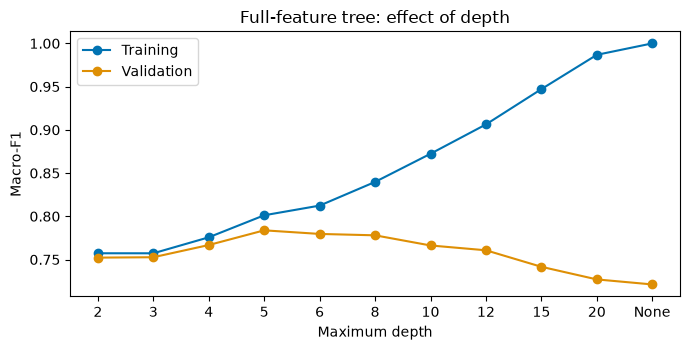

In [12]:
curve = tree_cv[(tree_cv['condition'] == 'full') & (tree_cv['min_samples_leaf'] == 1)]
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(curve['max_depth'], curve['train_macro_f1'], marker='o', label='Training')
ax.plot(curve['max_depth'], curve['cv_macro_f1'], marker='o', label='Validation')
ax.set(xlabel='Maximum depth', ylabel='Macro-F1', title='Full-feature tree: effect of depth')
ax.legend()
save_figure(fig, 'tree_overfitting')

## 7. Test-set evaluation and uncertainty

We refit each chosen model on the whole training set (fill-in values and the scaler come from training only) and score it once on the held-out test hosts.

**Baseline (0R / majority class).** In the training set the majority label is "not Superhost" (0). We predict 0 for every test listing. This is the ZeroR-style baseline from class. Any real model should beat it on the same metrics, and we report the improvement as a difference in macro-F1 (for example 0.39), not as a vague percentage.

**Metrics.** Accuracy, macro-F1, ROC-AUC, and per-class precision, recall and F1. ROC-AUC uses the predicted Superhost probability; 0.5 means ranking no better than chance. If a class is never predicted (the baseline never predicts Superhost), precision/recall for that class is 0.

**Uncertainty.** The specification asks for uncertainty on at least one metric. We use [`scipy.stats.bootstrap`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.bootstrap.html) to resample the test hosts 1,000 times, and take the 2.5% and 97.5% percentiles as a 95% interval for macro-F1. We resample whole hosts, not individual listings, because listings from the same host are not independent. Every model, including the baseline, is scored on the same 1,000 samples, so the interval for "model A minus model B" is a paired comparison. These intervals only describe variation in which test hosts we happened to hold out. They do not include uncertainty from retraining or retuning.

We use 1,000 resamples to limit runtime and `method='percentile'` to retain the existing interval method; SciPy's default is BCa, a different method. `scores_for_hosts` collects every listing of each sampled host and returns the macro-F1 for every model as an array ([`np.array`](https://numpy.org/doc/stable/reference/generated/numpy.array.html)). `vectorized=False` lets the helper handle one sample at a time; `batch=1` processes one resample per batch. [`np.arange`](https://numpy.org/doc/stable/reference/generated/numpy.arange.html) supplies host positions to sample. `bootstrap_distribution` contains the resampled scores; `.T` transposes it so each dataframe column is a model. Percentiles of the paired score differences give the comparison intervals. These choices assume hosts are sufficiently independent; they do not remove possible collection or geographic dependence.

**Function documentation:** [`to_numpy`](https://pandas.pydata.org/docs/reference/api/pandas.Series.to_numpy.html), [`predict_proba`](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsClassifier.html#sklearn.neighbors.KNeighborsClassifier.predict_proba), [`Series.mode`](https://pandas.pydata.org/docs/reference/api/pandas.Series.mode.html), [`np.full`](https://numpy.org/doc/stable/reference/generated/numpy.full.html), [`accuracy_score`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.accuracy_score.html), [`roc_auc_score`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.roc_auc_score.html), [`precision_recall_fscore_support`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.precision_recall_fscore_support.html), [`np.random.default_rng`](https://numpy.org/doc/stable/reference/random/generator.html), [`np.unique`](https://numpy.org/doc/stable/reference/generated/numpy.unique.html), [`np.where`](https://numpy.org/doc/stable/reference/generated/numpy.where.html), [`np.concatenate`](https://numpy.org/doc/stable/reference/generated/numpy.concatenate.html), [`Series.quantile`](https://pandas.pydata.org/docs/reference/api/pandas.Series.quantile.html).

In [13]:
def make_model(name, params):
    if name == 'knn':
        return KNeighborsClassifier(n_neighbors=params['n_neighbors'])
    return DecisionTreeClassifier(max_depth=params['max_depth'], min_samples_leaf=params['min_samples_leaf'],
                                  random_state=SEED)

def fit_and_predict(name, params, fit_rows, eval_rows, columns):
    X_fit, X_eval = impute(fit_rows, eval_rows, columns)
    if params.get('scaled', False):
        scaler = StandardScaler().fit(X_fit)
        X_fit, X_eval = scaler.transform(X_fit), scaler.transform(X_eval)
    model = make_model(name, params).fit(X_fit, fit_rows[TARGET])
    return model, model.predict(X_eval), model.predict_proba(X_eval)[:, 1]

MODELS = ['knn', 'decision_tree']
y_test = test_frame[TARGET].to_numpy()
fitted, predictions, probabilities = {}, {}, {}
for condition, columns in CONDITIONS.items():
    for name in MODELS:
        key = f'{condition}/{name}'
        fitted[key], predictions[key], probabilities[key] = fit_and_predict(
            name, chosen[condition, name], train_frame, test_frame, columns)

majority = train_frame[TARGET].mode()[0]
predictions['baseline'] = np.full(len(y_test), majority)
probabilities['baseline'] = np.full(len(y_test), float(majority))

In [14]:
# Host bootstrap: the same 1,000 resamples of test hosts are used for every model.
test_hosts = test_frame['host_id'].to_numpy()
unique_hosts = np.unique(test_hosts)
rows_of_host = [np.where(test_hosts == host)[0] for host in unique_hosts]   # row positions per host

model_keys = list(predictions)

def scores_for_hosts(sampled_hosts):
    # Keep all listings of each sampled host together and score every model.
    rows = np.concatenate([rows_of_host[h] for h in sampled_hosts])
    return np.array([
        f1_score(y_test[rows], predictions[key][rows], average='macro', zero_division=0)
        for key in model_keys
    ])

bootstrap_result = scipy_bootstrap(
    (np.arange(len(unique_hosts)),),
    scores_for_hosts,
    vectorized=False,
    n_resamples=1000,
    batch=1,
    confidence_level=0.95,
    method='percentile',
    rng=np.random.default_rng(SEED),
)

# One column per model; matching rows use the same sampled hosts.
bootstrap = pd.DataFrame(bootstrap_result.bootstrap_distribution.T, columns=model_keys)

baseline_f1 = f1_score(y_test, predictions['baseline'], average='macro', zero_division=0)
result_rows = []
for key, pred in predictions.items():
    precision, recall, f1, support = precision_recall_fscore_support(y_test, pred, zero_division=0)
    macro_f1 = f1_score(y_test, pred, average='macro', zero_division=0)
    result_rows.append({'model_condition': key, 'macro_f1': macro_f1,
                        'ci_lower': bootstrap[key].quantile(0.025), 'ci_upper': bootstrap[key].quantile(0.975),
                        'accuracy': accuracy_score(y_test, pred),
                        'roc_auc': roc_auc_score(y_test, probabilities[key]),
                        'gain_over_baseline': macro_f1 - baseline_f1,
                        'non_superhost_precision': precision[0], 'non_superhost_recall': recall[0],
                        'non_superhost_f1': f1[0], 'non_superhost_support': support[0],
                        'superhost_precision': precision[1], 'superhost_recall': recall[1],
                        'superhost_f1': f1[1], 'superhost_support': support[1]})
model_results = pd.DataFrame(result_rows)
show(model_results, 'model_results')

comparisons = []
for name in MODELS:
    comparisons += [(f'full/{name}', f'no_review/{name}'), (f'no_review/{name}', 'baseline')]
comparisons += [(f'{condition}/decision_tree', f'{condition}/knn') for condition in CONDITIONS]
test_f1 = model_results.set_index('model_condition')['macro_f1']
paired = []
for left, right in comparisons:
    difference = bootstrap[left] - bootstrap[right]
    paired.append({'left': left, 'right': right, 'difference': test_f1[left] - test_f1[right],
                   'ci_lower': difference.quantile(0.025), 'ci_upper': difference.quantile(0.975)})
show(pd.DataFrame(paired), 'paired_differences')

,model_condition,macro_f1,ci_lower,ci_upper,accuracy,roc_auc,gain_over_baseline,non_superhost_precision,non_superhost_recall,non_superhost_f1,non_superhost_support,superhost_precision,superhost_recall,superhost_f1,superhost_support
0,full/knn,0.781818,0.761631,0.801990,0.814808,0.882284,0.372295,0.865567,0.867750,0.866657,3569,0.698980,0.694990,0.696979,1577
1,full/decision_tree,0.799944,0.774095,0.822367,0.829382,0.891436,0.390420,0.878907,0.874475,0.876685,3569,0.719122,0.727330,0.723203,1577
2,no_review/knn,0.684373,0.656080,0.709813,0.740964,0.794190,0.274849,0.797657,0.839451,0.818020,3569,0.587770,0.518072,0.550725,1577
3,no_review/decision_tree,0.721444,0.694518,0.746664,0.753401,0.798060,0.311920,0.846386,0.787335,0.815793,3569,0.584337,0.676601,0.627094,1577
4,baseline,0.409524,0.390799,0.426393,0.693548,0.500000,0.000000,0.693548,1.000000,0.819048,3569,0.000000,0.000000,0.000000,1577


,left,right,difference,ci_lower,ci_upper
0,full/knn,no_review/knn,0.097446,0.077255,0.118952
1,no_review/knn,baseline,0.274849,0.243655,0.305550
2,full/decision_tree,no_review/decision_tree,0.078501,0.053700,0.103781
3,no_review/decision_tree,baseline,0.311920,0.280329,0.348379
4,full/decision_tree,full/knn,0.018126,0.001501,0.035034
5,no_review/decision_tree,no_review/knn,0.037071,0.014016,0.061353


The figure plots test macro-F1 for each feature set, with the 95% bootstrap interval as error bars. The grey dashed line is the majority-class baseline.

**Function documentation:** [`Axes.errorbar`](https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.errorbar.html), [`set_index`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.set_index.html), [`.loc`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.loc.html), [`np.arange`](https://numpy.org/doc/stable/reference/generated/numpy.arange.html), [`axhline`](https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.axhline.html), [`set_xticks`](https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.set_xticks.html).

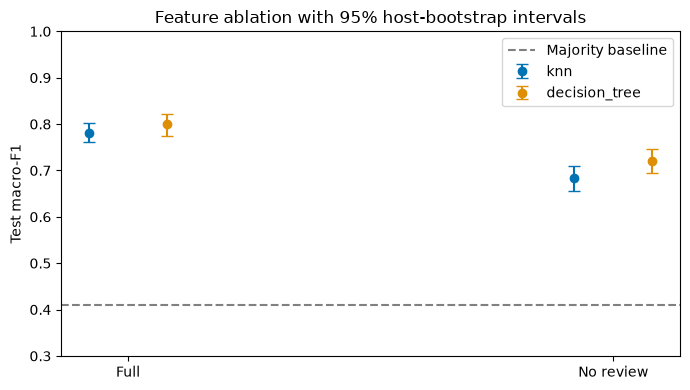

In [15]:
results_by_key = model_results.set_index('model_condition')
fig, ax = plt.subplots(figsize=(7, 4))
for name, offset in [('knn', -0.08), ('decision_tree', 0.08)]:
    rows = results_by_key.loc[[f'{condition}/{name}' for condition in CONDITIONS]]
    ax.errorbar(np.arange(len(CONDITIONS)) + offset, rows['macro_f1'],
                yerr=[rows['macro_f1'] - rows['ci_lower'], rows['ci_upper'] - rows['macro_f1']],
                fmt='o', capsize=4, label=name)
ax.axhline(baseline_f1, color='grey', linestyle='--', label='Majority baseline')
ax.set_xticks(range(len(CONDITIONS)), ['Full', 'No review'])
ax.set(ylabel='Test macro-F1', title='Feature ablation with 95% host-bootstrap intervals', ylim=(0.3, 1))
ax.legend()
save_figure(fig, 'feature_ablation')

## 8. Extra checks of model behaviour

The required comparison is still the test metrics in section 7. This section only explains where those scores come from.

**Subgroups.** Overall accuracy can hide a group the model always gets wrong. We therefore also score: never-reviewed vs reviewed listings; each collection date; and hosts with one test listing vs more than one. Small groups are descriptive only; we do not treat them as a second test set.

**Confusion matrix and ROC.** The confusion matrix counts true/false Superhost predictions for the full-feature models. The ROC curve plots the true positive rate against the false positive rate as we change the probability cutoff. The area under that curve is the ROC-AUC from section 7.

**Function documentation:** [`value_counts`](https://pandas.pydata.org/docs/reference/api/pandas.Series.value_counts.html), [`confusion_matrix`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.confusion_matrix.html), [`roc_curve`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.roc_curve.html).

`value_counts` counts test listings per host; `map` attaches each count to its rows. In row masks, `&` means both conditions and `|` means either. `labels=[0, 1]` scores both classes even when a subgroup has no Superhosts.

In [16]:
host_sizes = test_frame['host_id'].map(test_frame['host_id'].value_counts()).to_numpy()
scrape_dates = raw.loc[test_frame.index, 'last_scraped'].to_numpy()
subgroups = {'never_reviewed': test_frame['never_reviewed'].to_numpy() == 1,
             'reviewed': test_frame['never_reviewed'].to_numpy() == 0,
             'single_listing_host': host_sizes == 1,
             'multi_listing_host': host_sizes > 1}
for date in sorted(raw['last_scraped'].unique()):
    subgroups[f'scraped_{date}'] = scrape_dates == date

subgroup_rows = []
for key, pred in predictions.items():
    for group, mask in subgroups.items():
        if mask.sum() == 0:
            continue   # e.g. a collection date with no test listings
        precision, recall, _, _ = precision_recall_fscore_support(y_test[mask], pred[mask], labels=[0, 1], zero_division=0)
        subgroup_rows.append({'model_condition': key, 'subgroup': group, 'n': mask.sum(),
                              'positives': y_test[mask].sum(),
                              'accuracy': accuracy_score(y_test[mask], pred[mask]),
                              'macro_f1': f1_score(y_test[mask], pred[mask], labels=[0, 1], average='macro', zero_division=0),
                              'superhost_recall': recall[1], 'superhost_precision': precision[1]})
show(pd.DataFrame(subgroup_rows), 'subgroup_metrics')

,model_condition,subgroup,n,positives,accuracy,macro_f1,superhost_recall,superhost_precision
0,full/knn,never_reviewed,906,48,0.945916,0.486103,0.000000,0.000000
1,full/knn,reviewed,4240,1529,0.786792,0.770053,0.716808,0.699426
2,full/knn,single_listing_host,2277,540,0.867809,0.819273,0.737037,0.714542
3,full/knn,multi_listing_host,2869,1037,0.772743,0.752473,0.673095,0.690406
4,full/knn,scraped_2026-06-17,3784,1433,0.782505,0.771596,0.744592,0.700131
5,full/knn,scraped_2026-06-28,111,18,0.828829,0.571777,0.166667,0.428571
6,full/knn,scraped_2026-06-29,1251,126,0.911271,0.635781,0.206349,0.702703
7,full/decision_tree,never_reviewed,906,48,0.947020,0.486395,0.000000,0.000000
8,full/decision_tree,reviewed,4240,1529,0.804245,0.789674,0.750164,0.719122
9,full/decision_tree,single_listing_host,2277,540,0.907334,0.875006,0.840741,0.784111


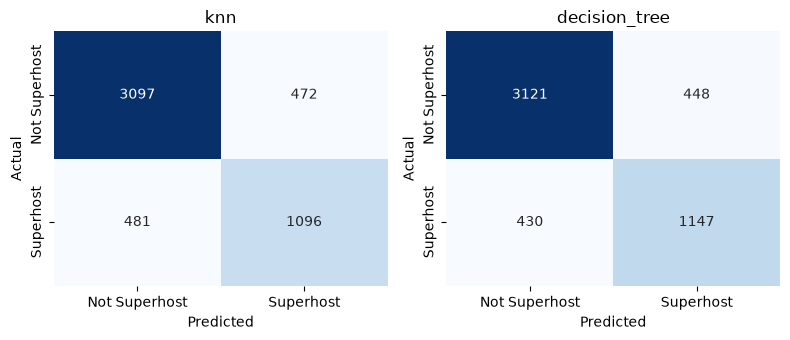

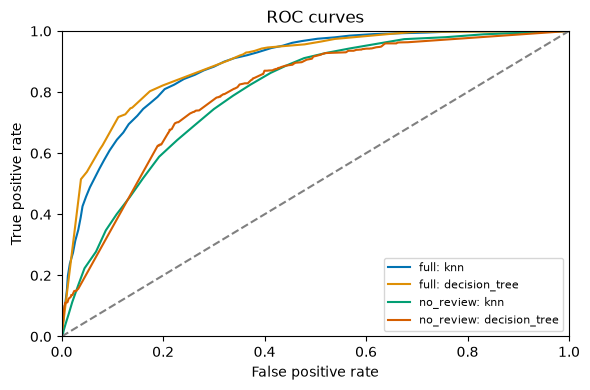

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3.5))
for ax, name in zip(axes, MODELS):
    matrix = confusion_matrix(y_test, predictions[f'full/{name}'])
    sns.heatmap(matrix, annot=True, fmt='d', cbar=False, cmap='Blues', ax=ax,
                xticklabels=['Not Superhost', 'Superhost'], yticklabels=['Not Superhost', 'Superhost'])
    ax.set(xlabel='Predicted', ylabel='Actual', title=name)
save_figure(fig, 'full_confusion_matrices')

fig, ax = plt.subplots(figsize=(6, 4))
for key in predictions:
    if key != 'baseline':
        false_positive_rate, true_positive_rate, _ = roc_curve(y_test, probabilities[key])
        ax.plot(false_positive_rate, true_positive_rate, label=key.replace('/', ': '))
ax.plot([0, 1], [0, 1], linestyle='--', color='grey')
ax.legend(fontsize=8)
ax.set(xlabel='False positive rate', ylabel='True positive rate', title='ROC curves', xlim=(0, 1), ylim=(0, 1))
save_figure(fig, 'roc_curves')

## 9. Training-only sensitivity checks

These checks measure the downstream effect of preprocessing choices (spec section 3.2 asks for a measurable before/after impact). They use only the five training folds with the selected hyperparameters held fixed, so they never look at the test set. They are exploratory comparisons, not new performance estimates, and fold differences are not independent, so the min/max range is descriptive rather than a confidence interval.

[`np.array`](https://numpy.org/doc/stable/reference/generated/numpy.array.html) stores the fold scores in an array so we can subtract them element by element. `cv_scores` returns the validation macro-F1 on each training fold for one model, feature list and data frame. The checks:

- drop recency, review frequency or the never-reviewed flag from the full set;
- in the `full` and `no_review` sets, drop price, beds and their missingness flags together to compare their contribution with and without review predictors (removing only the flag would leave the imputed value carrying the same signal);
- fill never-reviewed `reviews_per_month` with 0 instead of the median;
- train on reviewed listings only, evaluated on the same reviewed validation rows as the normal (all-listings) model, so only the training population changes.

In [18]:
def cv_scores(name, params, frame, columns, fold_list):
    scores = []
    for fit_idx, val_idx in fold_list:
        val_rows = frame.iloc[val_idx]
        _, pred, _ = fit_and_predict(name, params, frame.iloc[fit_idx], val_rows, columns)
        scores.append(f1_score(val_rows[TARGET], pred, average='macro'))
    return np.array(scores)

base_scores = {(condition, name): cv_scores(name, chosen[condition, name], train_frame, CONDITIONS[condition], folds)
               for condition in CONDITIONS for name in MODELS}

sensitivity_rows = []
def record(check, condition, name, base, alternative):
    for fold, (b, a) in enumerate(zip(base, alternative), start=1):
        sensitivity_rows.append({'check': check, 'condition': condition, 'model': name, 'fold': fold,
                                 'base_f1': b, 'alternative_f1': a, 'alternative_minus_base': a - b})

drop_checks = [('drop_recency', 'full', ['days_since_last_review']),
               ('drop_frequency', 'full', ['reviews_per_month']),
               ('drop_never_reviewed_indicator', 'full', ['never_reviewed']),
               ('drop_price_and_bed_fields', 'full', ['price_clean', 'price_missing', 'beds', 'beds_missing']),
               ('drop_price_and_bed_fields', 'no_review', ['price_clean', 'price_missing', 'beds', 'beds_missing'])]
for check, condition, removed in drop_checks:
    kept = [col for col in CONDITIONS[condition] if col not in removed]
    for name in MODELS:
        record(check, condition, name, base_scores[condition, name],
               cv_scores(name, chosen[condition, name], train_frame, kept, folds))

zero_filled = train_frame.copy()
zero_filled.loc[zero_filled['never_reviewed'] == 1, 'reviews_per_month'] = 0
for condition in ['full']:
    for name in MODELS:
        record('zero_fill_review_frequency', condition, name, base_scores[condition, name],
               cv_scores(name, chosen[condition, name], zero_filled, CONDITIONS[condition], folds))

# Reviewed-only training: both versions are scored on the reviewed validation rows only.
reviewed = train_frame['never_reviewed'].to_numpy() == 0
all_to_reviewed = [(fit_idx, val_idx[reviewed[val_idx]]) for fit_idx, val_idx in folds]
reviewed_to_reviewed = [(fit_idx[reviewed[fit_idx]], val_idx[reviewed[val_idx]]) for fit_idx, val_idx in folds]
for name in MODELS:
    params = chosen['full', name]
    record('reviewed_only_training', 'full', name,
           cv_scores(name, params, train_frame, CONDITIONS['full'], all_to_reviewed),
           cv_scores(name, params, train_frame, CONDITIONS['full'], reviewed_to_reviewed))

sensitivity = pd.DataFrame(sensitivity_rows)
sensitivity.to_csv('notebook_outputs/tables/sensitivity_by_fold.csv', index=False)
show(sensitivity.groupby(['check', 'condition', 'model'])
     .agg(base_mean=('base_f1', 'mean'), alternative_mean=('alternative_f1', 'mean'),
          mean_difference=('alternative_minus_base', 'mean'), min_difference=('alternative_minus_base', 'min'),
          max_difference=('alternative_minus_base', 'max'))
     .reset_index(), 'sensitivity_summary')

,check,condition,model,base_mean,alternative_mean,mean_difference,min_difference,max_difference
0,drop_frequency,full,decision_tree,0.784988,0.784868,-0.000119,-0.016588,0.024612
1,drop_frequency,full,knn,0.763323,0.750839,-0.012484,-0.020092,-0.005246
2,drop_never_reviewed_indicator,full,decision_tree,0.784988,0.784988,0.000000,0.000000,0.000000
3,drop_never_reviewed_indicator,full,knn,0.763323,0.746857,-0.016467,-0.026873,-0.010895
4,drop_price_and_bed_fields,full,decision_tree,0.784988,0.784988,0.000000,0.000000,0.000000
5,drop_price_and_bed_fields,full,knn,0.763323,0.770128,0.006805,0.000987,0.009153
6,drop_price_and_bed_fields,no_review,decision_tree,0.669279,0.668469,-0.000809,-0.013077,0.015897
7,drop_price_and_bed_fields,no_review,knn,0.648941,0.636502,-0.012439,-0.028978,0.007219
8,drop_recency,full,decision_tree,0.784988,0.771689,-0.013299,-0.021019,-0.006723
9,drop_recency,full,knn,0.763323,0.757385,-0.005939,-0.009063,-0.003666


## 10. Feature selection and a hard case

**Embedded method:** the fitted full-feature tree's [`feature_importances_`](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html#sklearn.tree.DecisionTreeClassifier.feature_importances_): how much each feature reduced Gini impurity across the tree's splits. A feature the tree never splits on scores 0, even if it carries information that another feature already supplied.

**Filter method:** [`mutual_info_classif`](https://scikit-learn.org/stable/modules/generated/sklearn.feature_selection.mutual_info_classif.html) scores each feature against the target separately, on the same imputed training matrix. `discrete_features` tells it which columns are treated as discrete values (counts, 0/1 flags, bathroom counts in half steps), so it counts those exactly; the review scores, review frequency, price and distance are continuous and use its nearest-neighbour estimate, which adds a little random noise (fixed by `random_state`). [`pd.factorize`](https://pandas.pydata.org/docs/reference/api/pandas.factorize.html) with `sort=True` numbers the distinct values 0, 1, 2, ... in sorted order. [`Series.rank`](https://pandas.pydata.org/docs/reference/api/pandas.Series.rank.html) with `ascending=False` turns scores into ranks (1 = highest); `method='min'` gives tied scores the same best rank. [`sort_values`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.sort_values.html) orders rows, [`nlargest`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.nlargest.html) takes the highest scores, and [`Axes.barh`](https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.barh.html) draws horizontal bars.

**Hard case.** After evaluation (so it plays no part in model choice), we look for a test listing that both full models misclassify and whose value for the tree's top feature is in the top or bottom 5% of all observed values. The percentile is the share of observed values at or below the listing's value.

,feature,declared_discrete,tree_importance,mi_nats,tree_rank,mi_rank
5,reviews_per_month,False,0.424339,0.133226,1,2
0,review_scores_rating,False,0.245148,0.118534,2,3
6,days_since_last_review,True,0.100751,0.156705,3,1
4,number_of_reviews,True,0.084944,0.110764,4,6
8,is_multi_listing_host,True,0.047153,0.012168,5,15
1,review_scores_cleanliness,False,0.040073,0.115394,6,4
7,host_listings_count,True,0.037509,0.113742,7,5
24,amenities_count,True,0.018902,0.073324,8,9
12,price_clean,False,0.001179,0.067328,9,10
9,host_identity_verified,True,0.000000,0.001111,10,25


Tree top three: ['reviews_per_month', 'review_scores_rating', 'days_since_last_review']
MI top three:   ['days_since_last_review', 'reviews_per_month', 'review_scores_rating']


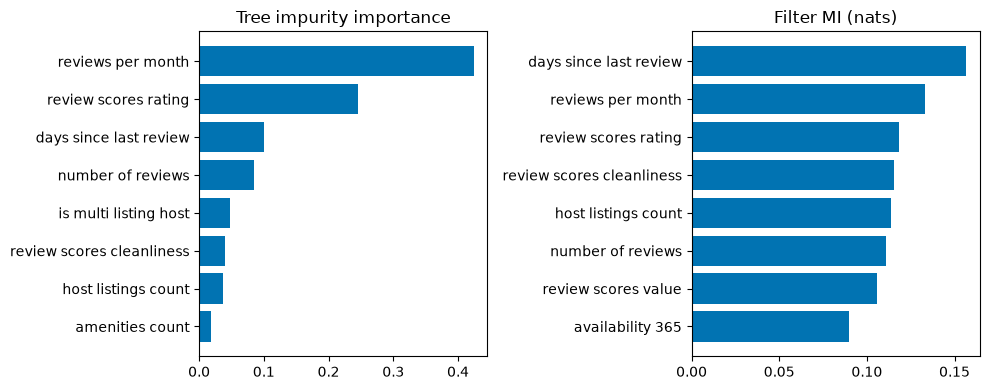

In [19]:
full_tree = fitted['full/decision_tree']
continuous = ['review_scores_rating', 'review_scores_cleanliness', 'review_scores_value',
              'reviews_per_month', 'price_clean', 'dist_cbd_km']
is_discrete = [col not in continuous for col in X_train_full.columns]
# Replace each distinct value of a discrete column by a whole-number code (e.g. 1.5 bathrooms -> code 3),
# because scikit-learn warns when "discrete" columns contain decimals. MI only depends on which rows
# share a value, so the codes give exactly the same MI.
X_mi = X_train_full.copy()
for col, discrete in zip(X_mi.columns, is_discrete):
    if discrete:
        X_mi[col] = pd.factorize(X_mi[col], sort=True)[0]
mi = mutual_info_classif(X_mi, train_frame[TARGET], discrete_features=is_discrete, random_state=SEED)

selection = pd.DataFrame({'feature': X_train_full.columns, 'declared_discrete': is_discrete,
                          'tree_importance': full_tree.feature_importances_, 'mi_nats': mi})
selection['tree_rank'] = selection['tree_importance'].rank(ascending=False, method='min').astype(int)
selection['mi_rank'] = selection['mi_nats'].rank(ascending=False, method='min').astype(int)
selection = selection.sort_values('tree_rank')
show(selection, 'feature_selection')
print('Tree top three:', selection.nlargest(3, 'tree_importance')['feature'].tolist())
print('MI top three:  ', selection.nlargest(3, 'mi_nats')['feature'].tolist())

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, column, title in zip(axes, ['tree_importance', 'mi_nats'], ['Tree impurity importance', 'Filter MI (nats)']):
    top = selection.nlargest(8, column).sort_values(column)
    ax.barh(top['feature'].str.replace('_', ' '), top[column])
    ax.set_title(title)
save_figure(fig, 'feature_selection')

In [20]:
top_feature = selection.iloc[0]['feature']
both_wrong = (predictions['full/knn'] != y_test) & (predictions['full/decision_tree'] != y_test)
cases = test_frame[both_wrong].copy()
cases['prediction_knn'] = predictions['full/knn'][both_wrong]
cases['prediction_decision_tree'] = predictions['full/decision_tree'][both_wrong]
cases['probability_knn'] = probabilities['full/knn'][both_wrong]
cases['probability_decision_tree'] = probabilities['full/decision_tree'][both_wrong]

observed = features[top_feature].dropna()
# Listings with a missing top-feature value get no percentile (NaN), so they are never tail cases.
cases['top_feature_percentile'] = cases[top_feature].dropna().apply(lambda value: (observed <= value).mean())
cases['tail_case'] = (cases['top_feature_percentile'] <= 0.05) | (cases['top_feature_percentile'] >= 0.95)
cases = cases.sort_values(['tail_case', 'id'], ascending=[False, True])

case_columns = ['id', 'host_id', TARGET, 'never_reviewed', 'number_of_reviews', 'reviews_per_month',
                'days_since_last_review', 'review_scores_rating', 'host_listings_count', 'availability_365',
                'price_missing', 'top_feature_percentile', 'prediction_knn', 'prediction_decision_tree',
                'probability_knn', 'probability_decision_tree']
show(cases[case_columns].head(10), 'hard_case_candidates')
selected = cases.iloc[0]
print('Selected listing:', selected['id'], '| top tree feature:', top_feature)

,id,host_id,host_is_superhost,never_reviewed,number_of_reviews,reviews_per_month,days_since_last_review,review_scores_rating,host_listings_count,availability_365,price_missing,top_feature_percentile,prediction_knn,prediction_decision_tree,probability_knn,probability_decision_tree
2068,16261169,46846051,0,0,211,4.32,38.0,4.95,1,60,0,0.954637,1,1,0.764706,0.820534
4393,29129681,168303034,1,0,1,0.01,2792.0,5.00,3,0,1,0.022964,0,0,0.039216,0.050633
6588,41693495,97093885,1,0,1,0.01,2314.0,5.00,18,364,0,0.022964,0,0,0.313725,0.050633
7729,50711628,235574374,1,0,1,0.02,1525.0,5.00,5,360,0,0.041127,0,0,0.333333,0.210526
8509,583684910175741610,449803755,0,0,211,4.21,30.0,4.84,1,267,0,0.951438,1,1,0.823529,0.820534
10102,772822383217535107,103268477,0,0,239,5.58,30.0,4.95,5,92,0,0.980330,1,1,0.823529,0.820534
10621,814358338667741636,103268477,0,0,238,5.81,27.0,4.90,5,83,0,0.983389,1,1,0.901961,0.820534
11970,923658693670578145,103268477,0,0,174,4.82,31.0,4.90,5,106,0,0.967954,1,1,0.705882,0.820534
13505,1040685070282929061,13512177,0,0,200,6.65,34.0,4.88,17,353,0,0.990165,1,1,0.843137,0.820534
16153,1239509071497079066,577868988,0,0,89,4.31,58.0,4.80,1,86,0,0.954402,1,1,0.725490,0.592242


Selected listing: 16261169 | top tree feature: reviews_per_month


The first three levels of the full tree ([`plot_tree`](https://scikit-learn.org/stable/modules/generated/sklearn.tree.plot_tree.html); `proportion=True` shows class shares instead of counts) show which thresholds the model uses.


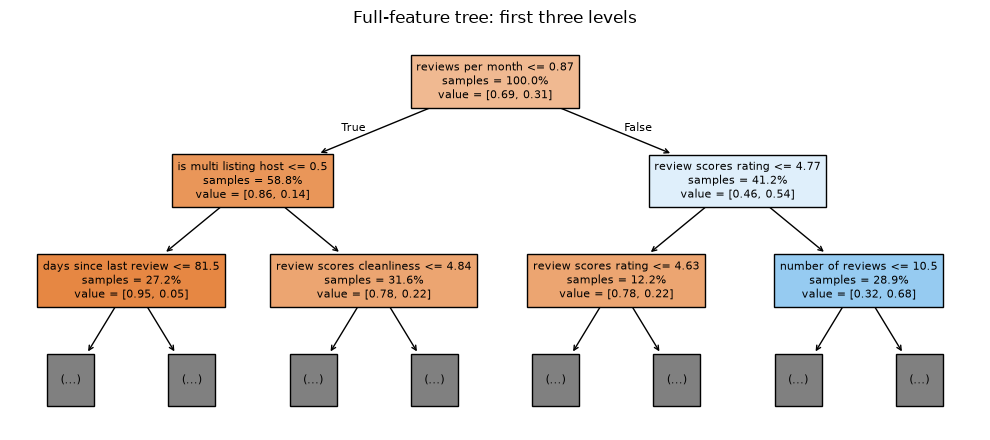

In [21]:
fig, ax = plt.subplots(figsize=(10, 4.5))
plot_tree(full_tree, feature_names=[col.replace('_', ' ') for col in CONDITIONS['full']], max_depth=2,
          filled=True, impurity=False, proportion=True, precision=2, fontsize=8, ax=ax)
ax.set_title('Full-feature tree: first three levels')
save_figure(fig, 'tree_top_levels')

A low-review Superhost listing is not necessarily a wrong label: the host may run other listings. The tree's rating threshold near 4.8 is suggestive, but listing reviews do not recover Airbnb's host-level eligibility rules, which use different quantities and time windows ([Airbnb's published requirements](https://www.airbnb.com/help/article/829) describe the current rules, not the historical decisions in this file).

## 11. Training-only KNN boundary check

**KNN grid boundary.** The selected k = 51 is the largest value in the grid, so we check larger k on the training folds. This does not change the selected model. [`np.round`](https://numpy.org/doc/stable/reference/generated/numpy.round.html) displays the fold scores to four decimals.


In [22]:
boundary = []
for k in [51, 71, 101, 151, 201]:
    scores = cv_scores('knn', {'n_neighbors': k, 'scaled': True}, train_frame, CONDITIONS['full'], folds)
    boundary.append({'k': k, 'mean_cv_macro_f1': scores.mean(), 'fold_scores': np.round(scores, 4).tolist()})
show(pd.DataFrame(boundary), 'knn_boundary_check')


,k,mean_cv_macro_f1,fold_scores
0,51,0.763323,"[0.7652, 0.7691, 0.7756, 0.7469, 0.7598]"
1,71,0.764134,"[0.7702, 0.7724, 0.775, 0.7427, 0.7603]"
2,101,0.763629,"[0.7743, 0.7719, 0.7722, 0.7394, 0.7604]"
3,151,0.760777,"[0.772, 0.7686, 0.7689, 0.736, 0.7583]"
4,201,0.760896,"[0.773, 0.7643, 0.7717, 0.7326, 0.7629]"


## 12. Notebook outputs for the report

| Report requirement | Output in `notebook_outputs/` |
|---|---|
| Collection dates and missingness | `collection_batches.csv`, `raw_missingness.csv` |
| Preprocessing candidates and measured changes | `preprocessing_candidates.csv`, `preprocessing_before_after.csv`, `sensitivity_summary.csv` |
| All four association methods, all ten pairs | `correlation_all_pairs.csv`, `correlation_training_only.csv` |
| Split justification | `split_balance.csv`, `cv_fold_balance.csv` |
| Every tuning score | `knn_grid_*.csv`, `tree_grid_*.csv`, `cv_results_*.csv`, `tuning_*.png` |
| Default, chosen setting and measured effect | `hyperparameter_effects.csv`, `tree_overfitting.png`, `knn_boundary_check.csv` |
| Models, per-class metrics, baseline, uncertainty | `model_results.csv`, `paired_differences.csv`, `feature_ablation.png`, confusion and ROC figures |
| Subgroups | `subgroup_metrics.csv` |
| Filter and embedded top features, hard case | `feature_selection.csv`, `feature_selection.png`, `hard_case_candidates.csv`, `tree_top_levels.png` |